In [1]:
from os.path import join, dirname
import os
import sys
import gc
import logging
import argparse
from copy import deepcopy
import numpy as np
import torchshow as ts
import torchvision
from einops import rearrange

import torch
from torch import autocast
from torch.cuda.amp import GradScaler
import torch.nn.functional as F
import torch.distributed as dist
import torch.multiprocessing as mp

sys.path.append(join(dirname(dirname(os.getcwd()))))
sys.path.append(os.getcwd())

from memoryPerceiver.memory_perceiver.main.configuration import cf
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_memories, reset_memories
from memoryPerceiver.memory_perceiver.core.distributed import setup_distributed, average_gradients, scatter_dummy_src, gather_dummy_src
from memoryPerceiver.memory_perceiver.core.miscellaneous import custom_random, print_cuda_tensors
import memoryPerceiver.memory_perceiver.isaac.trainer as tr
from memoryPerceiver.memory_perceiver.isaac.plot import Plotter
from memoryPerceiver.memory_perceiver.isaac.agent import ActorCritic, ActorCriticSimple, ActorCriticPerceiver, create_agent

from memoryPerceiver.memory_perceiver.core.model_net import PerceiverIO
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_multimodal_perceiver, output_projection, input_embedding

%load_ext autoreload
%autoreload 2

In [7]:
device = 'cuda:0'

In [20]:
memories = create_memories(model, cf.num_envs, device=device)

In [22]:
memories = torch.randn(128, 1, 1, 24, device=device)

In [16]:
model = create_multimodal_perceiver(cf, device)
states = {}
for i in range(4):
    states['observation_'+str(i)] = torch.ones(cf.num_envs, 1, 1, device=device)
x =input_embedding(model, states, device=device,
    height=cf.patch_height, width=cf.patch_width, patch_audio=cf.patch_audio)
print(x.shape)

torch.Size([128, 4, 24])


In [23]:
y, _ = model(x, memories, queries=model.queries)
output = output_projection(model, x, cf.frames_future, cf.audio_future)

torch.Size([128, 1, 1, 24])
torch.Size([128, 1, 24])
torch.Size([128, 1, 24])


In [81]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
memories = create_memories(model, cf.num_envs, device=device, 
                            nb_latents_mem=cf.nb_latents_mem)

In [82]:
loss_all=[]

In [83]:
for i in range(1000):
    tmp = torch.zeros(24, 1, 1, device=device)
    for i in range(4):
        tmp_i = torch.rand(24, 1, 1, device=device)
        tmp += tmp_i
        states['observation_'+str(i)] = tmp_i
    y_target =  tmp.detach()

    x = input_embedding(model, states, device=device,
            height=cf.patch_height, width=cf.patch_width, patch_audio=cf.patch_audio)
    y, _ = model(x, memories, queries=model.queries)
    output = output_projection(model, x, cf.frames_future, cf.audio_future)
    print('std', output['action_0'].std().item())

    loss = F.mse_loss(output['action_0'], y_target)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    # with torch.no_grad():  # No tracking of gradients during the update
    #     for param in model.parameters():
    #         if param.grad is not None:
    #             param -= 1e-4 * param.grad
    loss_all.append(loss.item())
    print(loss.item())

std 0.09073815494775772
5.186064720153809
std 0.11034442484378815
4.710019588470459
std 0.0919346958398819
4.435952663421631
std 0.08723641186952591
3.5556581020355225
std 0.09053841233253479
3.420032024383545
std 0.10279026627540588
3.582834243774414
std 0.09003248810768127
2.8241405487060547
std 0.06874395906925201
2.807171583175659
std 0.07533708959817886
2.8264212608337402
std 0.07110977172851562
2.2761178016662598
std 0.06409050524234772
1.9999103546142578
std 0.05359875410795212
2.2762489318847656
std 0.055215977132320404
1.9831721782684326
std 0.06329554319381714
1.6425056457519531
std 0.05580440163612366
1.294998049736023
std 0.050920043140649796
1.7260997295379639
std 0.05239450931549072
1.9260982275009155
std 0.04355957359075546
0.8888630867004395
std 0.04143640398979187
0.9714309573173523
std 0.030100993812084198
0.894371509552002
std 0.025620652362704277
0.7752234935760498
std 0.03389379382133484
1.2918261289596558
std 0.026684770360589027
0.934943675994873
std 0.0238520670

KeyboardInterrupt: 

In [84]:
from matplotlib import pyplot as plt

In [88]:
print(y_target[:5])

tensor([[[1.1026]],

        [[2.3436]],

        [[2.3372]],

        [[2.0335]],

        [[1.7228]]], device='cuda:0')


In [89]:
print(output['action_0'][:5])

tensor([[[2.3596]],

        [[1.5023]],

        [[2.0577]],

        [[2.2480]],

        [[2.3998]]], device='cuda:0', grad_fn=<SliceBackward0>)


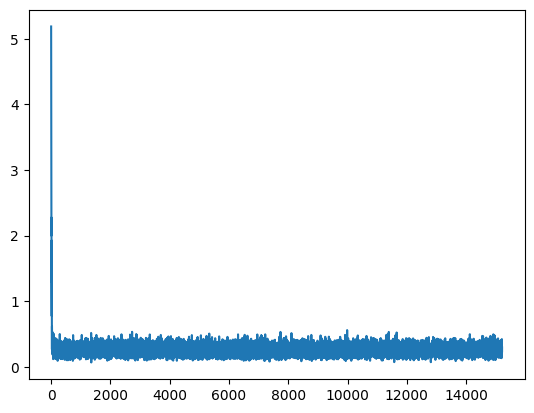

In [87]:
plt.plot(loss_all)